In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator
df = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/df_test_results_vectors_RMSE_LSTM_H4.parquet')

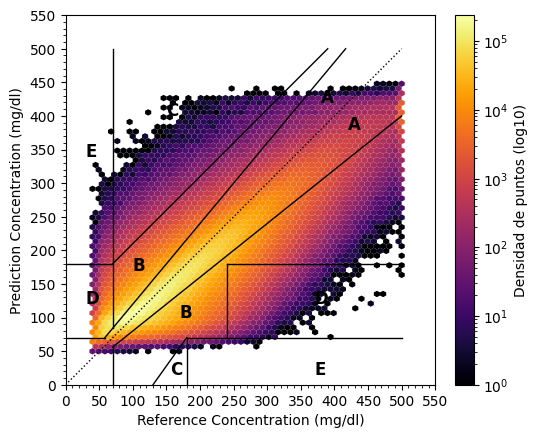

In [2]:

def clarke_error_grid_hexbin(ref_values,
                             pred_values,
                             title_string,
                             plot_dir='plots'):
    plt.clf()
    ax = plt.gca()

    # Configuración inicial del gráfico
    plt.gca().set_facecolor('white')
    plt.gca().set_xlim([0, 500])
    plt.gca().set_ylim([0, 500])
    plt.gca().set_aspect('equal')  # Importante para que los hexágonos sean regulares

    # -----------------------------------------------------------
    # 1. IMPLEMENTACIÓN HEXBIN (Reemplaza al scatter loop)
    # -----------------------------------------------------------

    # gridsize: ajusta este número. 50 suele ir bien (divide el eje en 50 hexágonos).
    # cmap: 'inferno', 'viridis', 'cividis' funcionan bien. 'inferno' resalta mucho los picos.
    # mincnt=1: hace que las zonas sin puntos sean transparentes (blancas).
    # bins='log': CRÍTICO. Usa escala logarítmica para el color. Si no lo usas,
    #             el pico de densidad ocultará los puntos raros (zonas D/E).

    hb = plt.hexbin(ref_values, pred_values,
                    gridsize=50,
                    cmap='inferno',
                    mincnt=1,
                    bins='log',
                    edgecolors='none')  # 'none' quita bordes al hexágono para suavizar

    # Añadimos la barra de color para entender la densidad
    cb = plt.colorbar(hb, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label('Densidad de puntos (log10)')

    # --- SECCIÓN ELIMINADA (Scatter manual por rangos) ---
    # colors = ['indianred', 'red', 'limegreen', 'yellow', 'orange']
    # masks = (...)
    # for m, c in zip(masks, colors):
    #     if np.any(m):
    #         ax.scatter(...)
    # -----------------------------------------------------

    plt.xlabel("Reference Concentration (mg/dl)")
    plt.ylabel("Prediction Concentration (mg/dl)")
    plt.xticks(np.arange(0, 551, 50))
    plt.yticks(np.arange(0, 551, 50))

    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))

    # -----------------------------------------------------------
    # 2. DIBUJO DE LÍNEAS (Tu código original intacto)
    # -----------------------------------------------------------
    # Plot zone lines
    plt.plot([0, 500], [0, 500], ':', c='black', linewidth=1)  # Línea 45°

    # LÍMITES DE ZONA D/E INFERIOR
    plt.plot([0, 175 / 3], [70, 70], '-', c='black', linewidth=1)
    plt.plot([175 / 3, 500 / 1.2], [70, 500], '-', c='black', linewidth=1)

    # LÍMITES VERTICALES IZQUIERDA
    plt.plot([70, 70], [84, 500], '-', c='black', linewidth=1)
    plt.plot([0, 70], [180, 180], '-', c='black', linewidth=1)

    # CORRECCIÓN #1
    plt.plot([70, 390], [180, 500], '-', c='black', linewidth=1)

    plt.plot([70, 70], [0, 56], '-', c='black', linewidth=1)

    # CORRECCIÓN #2
    plt.plot([70, 500], [56, 400], '-', c='black', linewidth=1)

    # RESTO DE LÍNEAS
    plt.plot([180, 180], [0, 70], '-', c='black', linewidth=1)
    plt.plot([180, 500], [70, 70], '-', c='black', linewidth=1)
    plt.plot([240, 240], [70, 180], '-', c='black', linewidth=1)
    plt.plot([240, 500], [180, 180], '-', c='black', linewidth=1)
    plt.plot([130, 180], [0, 70], '-', c='black', linewidth=1)

    # Add zone titles (Te sugiero ponerles un fondo blanco o un borde para que se lean sobre el color)
    zones = [
        (380, 420, "A"), (420, 380, "A"), (170, 100, "B"), (100, 170, "B"),
        (150, 400, "C"), (155, 15, "C"), (30, 120, "D"), (370, 120, "D"),
        (30, 340, "E"), (370, 15, "E")
    ]
    for x, y, txt in zones:
        plt.text(x, y, txt, fontsize=12, color='black', weight='bold')

    base = f'{plot_dir}/Clarke_Error_Grid_Hexbin{title_string}'
    plt.savefig(base + '.png', dpi=350, bbox_inches='tight')
    plt.savefig(base + '.pdf', bbox_inches='tight')

    import matplotlib as mpl
    mpl.rcParams['svg.fonttype'] = 'none'
    plt.savefig(base + '.svg', bbox_inches='tight')

clarke_error_grid_hexbin(ref_values=df['y_test'],
                                     pred_values=df['y_predict'],
                                     title_string='Test_hexbin')

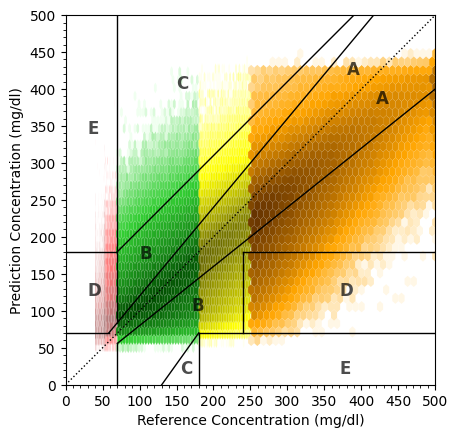

In [5]:
def clarke_error_grid_density_colored(ref_values, pred_values, title_string, plot_dir='plots'):
    plt.clf()
    ax = plt.gca()

    # 1. Definimos los colores base que ya usabas
    base_colors = ['indianred', 'red', 'limegreen', 'gold', 'darkorange']

    # Creamos colormaps que van desde un tono muy claro (casi blanco) hasta el color saturado
    # 'white' -> color_base -> negro (para zonas de máxima densidad)
    cmaps = [
        LinearSegmentedColormap.from_list("c1", ["#fff5f5", "indianred", "#5c1a1a"]),
        LinearSegmentedColormap.from_list("c2", ["#fff0f0", "red", "#660000"]),
        LinearSegmentedColormap.from_list("c3", ["#f0fff0", "limegreen", "#004d00"]),
        LinearSegmentedColormap.from_list("c4", ["#fffff0", "yellow", "#666600"]),
        LinearSegmentedColormap.from_list("c5", ["#fff7e6", "orange", "#663300"]),
    ]

    masks = (
        ref_values < 54,
        (ref_values >= 54) & (ref_values < 70),
        (ref_values >= 70) & (ref_values <= 180),
        (ref_values > 180) & (ref_values <= 250),
        (ref_values > 250),
    )

    # 2. Dibujamos un Hexbin por cada rango de glucosa
    for m, cmap in zip(masks, cmaps):
        if np.any(m):
            # Usamos hexbin solo para los datos de esa máscara
            ax.hexbin(ref_values[m], pred_values[m],
                      gridsize=30,
                      cmap=cmap,
                      mincnt=1,
                      bins='log',  # Escala logarítmica para ver bien los extremos
                      edgecolors='none')

    # --- Configuración estética (Igual que tu código) ---
    plt.xlabel("Reference Concentration (mg/dl)")
    plt.ylabel("Prediction Concentration (mg/dl)")
    plt.xticks(np.arange(0, 551, 50))
    plt.yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    plt.gca().set_facecolor('white')
    plt.gca().set_xlim([0, 500])
    plt.gca().set_ylim([0, 500])
    plt.gca().set_aspect('equal')

    # 3. Dibujo de líneas del Clarke Error Grid (Tus líneas originales)
    line_params = {'c': 'black', 'linewidth': 1}
    plt.plot([0, 500], [0, 500], ':', **line_params)
    plt.plot([0, 175 / 3], [70, 70], '-', **line_params)
    plt.plot([175 / 3, 500 / 1.2], [70, 500], '-', **line_params)
    plt.plot([70, 70], [84, 500], '-', **line_params)
    plt.plot([0, 70], [180, 180], '-', **line_params)
    plt.plot([70, 390], [180, 500], '-', **line_params)
    plt.plot([70, 70], [0, 56], '-', **line_params)
    plt.plot([70, 500], [56, 400], '-', **line_params)
    plt.plot([180, 180], [0, 70], '-', **line_params)
    plt.plot([180, 500], [70, 70], '-', **line_params)
    plt.plot([240, 240], [70, 180], '-', **line_params)
    plt.plot([240, 500], [180, 180], '-', **line_params)
    plt.plot([130, 180], [0, 70], '-', **line_params)

    # Títulos de zonas
    zones = [(380, 420, "A"), (420, 380, "A"), (170, 100, "B"), (100, 170, "B"),
             (150, 400, "C"), (155, 15, "C"), (30, 120, "D"), (370, 120, "D"),
             (30, 340, "E"), (370, 15, "E")]
    for x, y, txt in zones:
        plt.text(x, y, txt, fontsize=12, fontweight='bold', alpha=0.7)

    # Guardar
    plt.savefig(f'{plot_dir}/CEG_Density_Colored_{title_string}.png', dpi=300, bbox_inches='tight')

clarke_error_grid_density_colored(ref_values=df['y_test'],
                                     pred_values=df['y_predict'],
                                     title_string='Test_heatmap_single_log_YlOrRd_bins500')

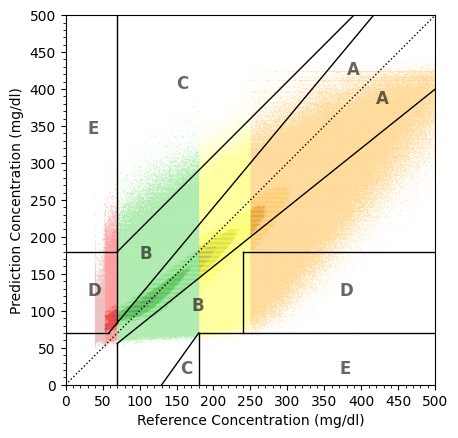

In [13]:
def clarke_error_grid_uniform_hex(ref_values, pred_values, title_string, plot_dir='plots'):
    plt.clf()
    ax = plt.gca()

    # 1. Definimos los colormaps (de claro a oscuro) para cada rango
    cmaps = [
        LinearSegmentedColormap.from_list("c1", ["#fff5f5", "indianred", "#5c1a1a"]),
        LinearSegmentedColormap.from_list("c2", ["#fff0f0", "red", "#660000"]),
        LinearSegmentedColormap.from_list("c3", ["#f0fff0", "limegreen", "#004d00"]),
        LinearSegmentedColormap.from_list("c4", ["#fffff0", "yellow", "#666600"]),
        LinearSegmentedColormap.from_list("c5", ["#fff7e6", "orange", "#663300"]),
    ]

    masks = (
        ref_values < 54,
        (ref_values >= 54) & (ref_values < 70),
        (ref_values >= 70) & (ref_values <= 180),
        (ref_values > 180) & (ref_values <= 250),
        (ref_values > 250),
    )

    # --- PARÁMETROS DE UNIFORMIDAD ---
    # gridsize: Cuántos hexágonos caben en el eje X.
    # extent: [xmin, xmax, ymin, ymax]. Esto es lo que iguala el tamaño en todo el rango.
    g_size = 500
    g_extent = [0, 500, 0, 500]

    # 2. Dibujamos cada zona
    for m, cmap in zip(masks, cmaps):
        if np.any(m):
            ax.hexbin(ref_values[m], pred_values[m],
                      gridsize=g_size,
                      extent=g_extent, # <--- CRÍTICO: misma base para todos
                      cmap=cmap,
                      mincnt=1,
                      # bins='log',
                      bins=5,
                      edgecolors='none')

    # 3. Estética y límites (Tu configuración original)
    plt.xlabel("Reference Concentration (mg/dl)")
    plt.ylabel("Prediction Concentration (mg/dl)")
    plt.xticks(np.arange(0, 551, 50))
    plt.yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    # 4. Líneas del Clarke Error Grid
    lp = {'c': 'black', 'linewidth': 1, 'zorder': 5} # zorder alto para que las líneas queden sobre los hexágonos
    plt.plot([0, 500], [0, 500], ':', **lp)
    plt.plot([0, 175/3], [70, 70], '-', **lp)
    plt.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    plt.plot([70, 70], [84, 500], '-', **lp)
    plt.plot([0, 70], [180, 180], '-', **lp)
    plt.plot([70, 390], [180, 500], '-', **lp)
    plt.plot([70, 70], [0, 56], '-', **lp)
    plt.plot([70, 500], [56, 400], '-', **lp)
    plt.plot([180, 180], [0, 70], '-', **lp)
    plt.plot([180, 500], [70, 70], '-', **lp)
    plt.plot([240, 240], [70, 180], '-', **lp)
    plt.plot([240, 500], [180, 180], '-', **lp)
    plt.plot([130, 180], [0, 70], '-', **lp)

    # Títulos de zonas
    zones = [(380,420,"A"),(420,380,"A"),(170,100,"B"),(100,170,"B"),
             (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
             (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones:
        plt.text(x, y, txt, fontsize=12, fontweight='bold', alpha=0.6, zorder=6)

    plt.savefig(f'{plot_dir}/CEG_Perfect_Grid_{title_string}.png', dpi=300, bbox_inches='tight')

clarke_error_grid_uniform_hex(ref_values=df['y_test'],
                                     pred_values=df['y_predict'],
                                     title_string='Hexbin_Uniform_Grid_500_bins5')

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LinearSegmentedColormap

def clarke_error_grid_hex_param_search(ref_values, pred_values, title_string, g_size, bin_val, plot_dir='plots_hex'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(8, 8))

    # --- 1. FONDO DE RANGOS (ZONIFICADO) ---
    zones_bg = [
        (0, 54, 'indianred', 'TBR_2'),
        (54, 70, 'red', 'TBR_1'),
        (70, 180, 'seagreen', 'TIR'), 
        (180, 250, 'gold', 'TAR_1'),
        (250, 500, 'orange', 'TAR_2')
    ]

    for start, end, color, label in zones_bg:
        ax.axvspan(start, end, facecolor=color, alpha=0.15, zorder=0)
        # Etiquetas tipo burbuja en la parte superior
        mid_point = (start + end) / 2
        ax.text(mid_point, 475, label, color=color, fontsize=9, 
                fontweight='bold', ha='center', va='center',
                bbox=dict(facecolor='white', alpha=0.9, edgecolor=color, 
                          boxstyle='round,pad=0.3', linewidth=1),
                zorder=15)

    # --- 2. CONFIGURACIÓN DE HEXBIN ---
    cmaps = [
        LinearSegmentedColormap.from_list("c1", ["#fff5f5", "indianred", "#5c1a1a"]),
        LinearSegmentedColormap.from_list("c2", ["#fff0f0", "red", "#660000"]),
        LinearSegmentedColormap.from_list("c3", ["#f0fff0", "seagreen", "#004d00"]),
        LinearSegmentedColormap.from_list("c4", ["#fffff0", "gold", "#666600"]),
        LinearSegmentedColormap.from_list("c5", ["#fff7e6", "orange", "#663300"]),
    ]

    masks = (
        ref_values < 54,
        (ref_values >= 54) & (ref_values < 70),
        (ref_values >= 70) & (ref_values <= 180),
        (ref_values > 180) & (ref_values <= 250),
        (ref_values > 250),
    )

    g_extent = [0, 500, 0, 500]

    for m, cmap in zip(masks, cmaps):
        if np.any(m):
            ax.hexbin(ref_values[m], pred_values[m],
                      gridsize=g_size,
                      extent=g_extent,
                      cmap=cmap,
                      mincnt=1,
                      bins=bin_val, # Aquí pasará 'log' o el entero
                      edgecolors='none',
                      zorder=3)

    # --- 3. LÍNEAS DEL CEG (NEGRAS) ---
    lp = {'c': 'black', 'linewidth': 1, 'zorder': 10, 'alpha': 0.5}
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Etiquetas de zonas A-E
    zones_ceg = [(380,430,"A"),(430,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
                 (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, color='black', fontsize=12, fontweight='black', zorder=12)

    # Estética de ejes
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xlim([0, 500]); ax.set_ylim([0, 500])
    ax.set_aspect('equal')
    ax.xaxis.set_major_locator(MultipleLocator(50))
    ax.yaxis.set_major_locator(MultipleLocator(50))

    # Nombre del archivo dinámico
    bin_str = f"bin_{bin_val}" if bin_val != 'log' else "bin_log"
    filename = f"{plot_dir}/Hex_G{g_size}_{bin_str}_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# --- BUCLE DE PRUEBAS ---

g_sizes = [100, 200, 300, 400, 500]
bins_options = ['log'] + list(range(5, 51, 5))

for gs in g_sizes:
    for bo in bins_options:
        print(f"Generando Hexbin: GSize={gs}, Bins={bo}")
        clarke_error_grid_hex_param_search(
            df['y_test'], df['y_predict'], "HexSearch", gs, bo
        )

Generando Hexbin: GSize=100, Bins=log
Generando Hexbin: GSize=100, Bins=5
Generando Hexbin: GSize=100, Bins=10
Generando Hexbin: GSize=100, Bins=15
Generando Hexbin: GSize=100, Bins=20
Generando Hexbin: GSize=100, Bins=25
Generando Hexbin: GSize=100, Bins=30
Generando Hexbin: GSize=100, Bins=35
Generando Hexbin: GSize=100, Bins=40
Generando Hexbin: GSize=100, Bins=45
Generando Hexbin: GSize=100, Bins=50
Generando Hexbin: GSize=200, Bins=log
Generando Hexbin: GSize=200, Bins=5
Generando Hexbin: GSize=200, Bins=10
Generando Hexbin: GSize=200, Bins=15
Generando Hexbin: GSize=200, Bins=20
Generando Hexbin: GSize=200, Bins=25
Generando Hexbin: GSize=200, Bins=30
Generando Hexbin: GSize=200, Bins=35
Generando Hexbin: GSize=200, Bins=40
Generando Hexbin: GSize=200, Bins=45
Generando Hexbin: GSize=200, Bins=50
Generando Hexbin: GSize=300, Bins=log
Generando Hexbin: GSize=300, Bins=5
Generando Hexbin: GSize=300, Bins=10
Generando Hexbin: GSize=300, Bins=15
Generando Hexbin: GSize=300, Bins=20
G

<Figure size 640x480 with 0 Axes>

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LinearSegmentedColormap

def clarke_error_grid_uniform_hex(ref_values, pred_values, title_string, g_size, bin_val, plot_dir='plots_hex_test'):
    # Crear carpeta si no existe
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    ax = plt.gca()

    # 1. Definimos los colormaps (de claro a oscuro) para cada rango
    cmaps = [
        LinearSegmentedColormap.from_list("c1", ["#fff5f5", "indianred", "#5c1a1a"]),
        LinearSegmentedColormap.from_list("c2", ["#fff0f0", "red", "#660000"]),
        LinearSegmentedColormap.from_list("c3", ["#f0fff0", "limegreen", "#004d00"]),
        LinearSegmentedColormap.from_list("c4", ["#fffff0", "yellow", "#666600"]),
        LinearSegmentedColormap.from_list("c5", ["#fff7e6", "orange", "#663300"]),
    ]

    masks = (
        ref_values < 54,
        (ref_values >= 54) & (ref_values < 70),
        (ref_values >= 70) & (ref_values <= 180),
        (ref_values > 180) & (ref_values <= 250),
        (ref_values > 250),
    )

    # --- PARÁMETROS DE UNIFORMIDAD PARAMETRIZADOS ---
    g_extent = [0, 500, 0, 500]

    # 2. Dibujamos cada zona
    for m, cmap in zip(masks, cmaps):
        if np.any(m):
            ax.hexbin(ref_values[m], pred_values[m],
                      gridsize=g_size,
                      extent=g_extent,
                      cmap=cmap,
                      mincnt=1,
                      bins=bin_val, # Parámetro dinámico
                      edgecolors='none')

    # 3. Estética y límites
    plt.xlabel("Reference Concentration (mg/dl)")
    plt.ylabel("Prediction Concentration (mg/dl)")
    plt.xticks(np.arange(0, 551, 50))
    plt.yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    # 4. Líneas del Clarke Error Grid
    lp = {'c': 'black', 'linewidth': 1, 'zorder': 5}
    plt.plot([0, 500], [0, 500], ':', **lp)
    plt.plot([0, 175/3], [70, 70], '-', **lp)
    plt.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    plt.plot([70, 70], [84, 500], '-', **lp)
    plt.plot([0, 70], [180, 180], '-', **lp)
    plt.plot([70, 390], [180, 500], '-', **lp)
    plt.plot([70, 70], [0, 56], '-', **lp)
    plt.plot([70, 500], [56, 400], '-', **lp)
    plt.plot([180, 180], [0, 70], '-', **lp)
    plt.plot([180, 500], [70, 70], '-', **lp)
    plt.plot([240, 240], [70, 180], '-', **lp)
    plt.plot([240, 500], [180, 180], '-', **lp)
    plt.plot([130, 180], [0, 70], '-', **lp)

    # Títulos de zonas
    zones = [(380,420,"A"),(420,380,"A"),(170,100,"B"),(100,170,"B"),
             (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
             (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones:
        plt.text(x, y, txt, fontsize=12, fontweight='bold', alpha=0.6, zorder=6)

    # Nombre de archivo dinámico para identificar la prueba
    bin_str = f"bin{bin_val}" if bin_val != 'log' else "binLOG"
    plt.savefig(f'{plot_dir}/Hex_G{g_size}_{bin_str}_{title_string}.png', dpi=300, bbox_inches='tight')
    plt.close()

# --- EJECUCIÓN DE LOS BUCLES DE PRUEBA ---

g_sizes = [50 , 75, 85]
bins_options = ['log'] + list(range(1, 31, 1))

for gs in g_sizes:
    for bo in bins_options:
        clarke_error_grid_uniform_hex(
            ref_values=df['y_test'],
            pred_values=df['y_predict'],
            title_string='Test_Grid',
            g_size=gs,
            bin_val=bo
        )

In [ ]:
# con leyenda
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm, LogNorm

def clarke_error_grid_uniform_hex(ref_values, pred_values, title_string, g_size, bin_val, plot_dir='plots_hex_test'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(10, 8))

    # 1. CÁLCULO DE LÍMITES REALES
    # Primero sacamos el conteo máximo de puntos que hay en un hexágono
    hb_temp = ax.hexbin(ref_values, pred_values, gridsize=g_size, extent=[0, 500, 0, 500], mincnt=1, visible=False)
    counts = hb_temp.get_array()
    max_count = counts.max()
    hb_temp.remove()

    # 2. CREACIÓN DE LA ESCALA (NORM)
    if bin_val == 'log':
        norm = LogNorm(vmin=1, vmax=max_count)
        boundaries = np.logspace(0, np.log10(max_count), 10) # Para la leyenda log
    else:
        # Creamos 'escalones' lineales basados en el número de bins
        # Esto define exactamente cuántos puntos entran en cada color
        boundaries = np.linspace(1, max_count, bin_val + 1)
        norm = BoundaryNorm(boundaries, ncolors=256)

    cmaps = [
        LinearSegmentedColormap.from_list("c1", ["#fff5f5", "indianred", "#5c1a1a"]),
        LinearSegmentedColormap.from_list("c2", ["#fff0f0", "red", "#660000"]),
        LinearSegmentedColormap.from_list("c3", ["#f0fff0", "limegreen", "#004d00"]),
        LinearSegmentedColormap.from_list("c4", ["#fffff0", "yellow", "#666600"]),
        LinearSegmentedColormap.from_list("c5", ["#fff7e6", "orange", "#663300"]),
    ]

    masks = (
        ref_values < 54,
        (ref_values >= 54) & (ref_values < 70),
        (ref_values >= 70) & (ref_values <= 180),
        (ref_values > 180) & (ref_values <= 250),
        (ref_values > 250),
    )

    # 3. DIBUJAR
    for m, cmap in zip(masks, cmaps):
        if np.any(m):
            ax.hexbin(ref_values[m], pred_values[m],
                      gridsize=g_size,
                      extent=[0, 500, 0, 500],
                      cmap=cmap,
                      mincnt=1,
                      norm=norm, # Usamos la escala de escalones calculada
                      edgecolors='none')

    # 4. LEYENDA CON NÚMEROS REALES
    sm = plt.cm.ScalarMappable(norm=norm, cmap='Greys')
    cb = fig.colorbar(sm, ax=ax, pad=0.04, ticks=boundaries) 
    
    # Esto pone los números exactos de los 'escalones' en la leyenda
    cb.set_label('Cantidad exacta de puntos por hexágono')

    # --- ESTÉTICA Y LÍNEAS (IGUAL) ---
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xlim([0, 500]); ax.set_ylim([0, 500])
    ax.set_aspect('equal')
    lp = {'c': 'black', 'linewidth': 1, 'zorder': 10, 'alpha': 0.6}
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    bin_str = f"bin{bin_val}" if bin_val != 'log' else "binLOG"
    plt.savefig(f'{plot_dir}/Hex_G{g_size}_{bin_str}_{title_string}.png', dpi=300, bbox_inches='tight')
    plt.close()

# Bucle
g_sizes = [50, 75, 85] + list(range(100, 501, 100))
bins_options = list(range(1, 21, 1))

for gs in g_sizes:
    for bo in bins_options:
        clarke_error_grid_uniform_hex(df['y_test'], df['y_predict'], 'Grid_Search', gs, bo)

In [4]:
# Solo log
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LinearSegmentedColormap, LogNorm

def clarke_error_grid_log_hex(ref_values, pred_values, title_string, g_size, plot_dir='plots_hex_log'):
    # Crear carpeta si no existe
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(10, 8))

    # 1. CÁLCULO DE LÍMITES PARA SINCRONIZAR COLORES
    # Escaneamos todos los datos para encontrar el valor máximo de densidad
    hb_setup = ax.hexbin(ref_values, pred_values, gridsize=g_size, extent=[0, 500, 0, 500], bins='log', visible=False)
    v_min, v_max = hb_setup.get_clim()
    hb_setup.remove()

    # Definimos los colormaps (Idénticos a los tuyos)
    cmaps = [
        LinearSegmentedColormap.from_list("c1", ["#fff5f5", "indianred", "#5c1a1a"]),
        LinearSegmentedColormap.from_list("c2", ["#fff0f0", "red", "#660000"]),
        LinearSegmentedColormap.from_list("c3", ["#f0fff0", "limegreen", "#004d00"]),
        LinearSegmentedColormap.from_list("c4", ["#fffff0", "yellow", "#666600"]),
        LinearSegmentedColormap.from_list("c5", ["#fff7e6", "orange", "#663300"]),
    ]

    masks = (
        ref_values < 54,
        (ref_values >= 54) & (ref_values < 70),
        (ref_values >= 70) & (ref_values <= 180),
        (ref_values > 180) & (ref_values <= 250),
        (ref_values > 250),
    )

    # 2. DIBUJO DE ZONAS CON ESCALA LOGARÍTMICA SINCRONIZADA
    for m, cmap in zip(masks, cmaps):
        if np.any(m):
            # Usamos LogNorm para que la intensidad del color sea logarítmica
            hb = ax.hexbin(ref_values[m], pred_values[m],
                          gridsize=g_size,
                          extent=[0, 500, 0, 500],
                          cmap=cmap,
                          mincnt=1,
                          bins='log',
                          vmin=v_min,
                          vmax=v_max,
                          edgecolors='none')

    # 3. LEYENDA LOGARÍTMICA NATURAL
    # Usamos un mapa de grises para la referencia numérica de densidad
    sm = plt.cm.ScalarMappable(norm=LogNorm(vmin=v_min, vmax=v_max), cmap='Greys')
    cb = fig.colorbar(sm, ax=ax, pad=0.04)
    cb.set_label('Densidad de puntos (Escala Logarítmica)')

    # 4. ESTÉTICA Y LÍNEAS DEL CEG
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 551, 50))
    ax.set_yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    lp = {'c': 'black', 'linewidth': 1, 'zorder': 10, 'alpha': 0.6}
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    zones = [(380,420,"A"),(420,380,"A"),(170,100,"B"),(100,170,"B"),
             (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
             (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones:
        ax.text(x, y, txt, fontsize=12, fontweight='bold', alpha=0.6, zorder=11)

    plt.savefig(f'{plot_dir}/Hex_G{g_size}_LogScale_{title_string}.png', dpi=300, bbox_inches='tight')
    plt.close()

# --- BUCLE DE PRUEBA ESPECÍFICO PARA LOG ---
g_sizes = list(range(100, 501, 100))

for gs in g_sizes:
    clarke_error_grid_log_hex(df['y_test'], df['y_predict'], 'Final_Log_Report', gs)

<Figure size 640x480 with 0 Axes>